# Atlas: verification and research experiments

**Research question.** Under a specified synthetic balance sheet and loan network, how do exogenous credit events and assumed recovery affect modeled direct counterparty contagion?

This is a computational experiment, not an estimate of actual bank failure probabilities. Historical S&P 500 observations enter only as an optional scenario magnitude. The contribution demonstrated here is a reproducible and inspectable workflow using established model ideas; algorithmic novelty and forecasting accuracy are not claimed.

Run this notebook after installing the locked project environment. Every output below is computed from the displayed inputs. Monetary quantities are synthetic nominal INR crore. No live data service is needed.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from atlas.baseline import direct_loss_only
from atlas.models import Bank, Dataset, Exposure, Scenario
from atlas.generate import generate
from atlas.engine import bank_risk, credit_risk, furfine, monte_carlo
from atlas.market import calibration
from atlas.storage import dataset_hash, experiment, save_experiment
from atlas.analysis import exposure_matrix, graph_metrics, impact_ranking, topology_ensemble, monte_carlo_summary

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
OUTPUT = ROOT / "experiments" / "research"
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 20)


## 1. Independent arithmetic check: a three-bank chain

A lends 100 to B; C lends 80 to A. Initial equity is 50, 50 and 40 for A, B and C respectively. B is forced into default as an external credit event. At recovery 40%, A loses `100 × 0.6 = 60`, exhausting its equity to −10; then C loses `80 × 0.6 = 48`, exhausting its equity to −8. The expected posted loan loss is 108 and there are two secondary defaults.

A forced default is an assumed credit event: it does not mechanically erase B's book equity. The resulting ledger is not a full resolution balance sheet.

In [2]:
chain = Dataset(topology="manual_chain", banks=[
    Bank(id="A", name="A", external_assets=100, interbank_assets=100,
         interbank_liabilities=80, deposits=70, equity=50),
    Bank(id="B", name="B", external_assets=200, interbank_assets=0,
         interbank_liabilities=100, deposits=50, equity=50),
    Bank(id="C", name="C", external_assets=100, interbank_assets=80,
         interbank_liabilities=0, deposits=140, equity=40),
], exposures=[Exposure(lender="A", borrower="B", amount=100),
              Exposure(lender="C", borrower="A", amount=80)])
verified = furfine(chain, Scenario(name="Hand-calculated chain", initial_defaults=["B"], recovery=0.4))
assert verified["defaults"] == ["A", "B", "C"]
assert np.isclose(verified["interbank_loss"], 108)
assert verified["equity"]["A"] == -10 and verified["equity"]["C"] == -8
assert np.isclose(credit_risk(chain).expected_loss.sum(), 2.16)
display(pd.DataFrame([{k: r[k] for k in ["round", "new_defaults", "cumulative_defaults", "interbank_loss"]} for r in verified["rounds"]]))


,round,new_defaults,cumulative_defaults,interbank_loss
0,0,[B],1,0.0
1,1,[A],2,60.0
2,2,[C],3,48.0
3,3,[],3,0.0


### Trace individual loan losses

The event table lists every recognized loan-loss contribution. It reconciles to bank-level and aggregate posted losses. Zero-loss events at full recovery are valid; claims of already defaulted creditors are excluded by the model convention.

In [3]:
events = pd.DataFrame(verified["events"])
assert np.isclose(events.loss.sum(), verified["interbank_loss"])
for lender, amount in verified["bank_interbank_loss"].items():
    assert np.isclose(events.loc[events.lender == lender, "loss"].sum(), amount)
display(events)
events.to_csv(OUTPUT / "chain_loan_events.csv", index=False)


,round,lender,borrower,ead,loss
0,1,A,B,100.0,60.0
1,2,C,A,80.0,48.0


## 2. Bank explorer, directed exposures and structural metrics

The matrix row is the lender and the column the borrower. Its row sums must equal interbank assets and column sums interbank liabilities. Debt losses propagate in the reverse direction to lending arrows. Graph centrality describes structural position; it is not a substitute for measuring the consequences of a specified default scenario.

In [4]:
data = generate(50, 42, "core_periphery")
risk = bank_risk(data)
matrix = exposure_matrix(data)
metrics = graph_metrics(data)
print("Dataset fingerprint:", dataset_hash(data))
display(risk.head())
display(matrix.iloc[:8, :8])
display(pd.DataFrame([{k: v for k, v in metrics.items() if k != "bank_metrics"}]))
display(pd.DataFrame(metrics["bank_metrics"]).head())
selected = "B001"
print("Selected bank:", selected)
display(risk[risk.id == selected])
display(credit_risk(data).query("lender == @selected or borrower == @selected"))


Dataset fingerprint: c6948be98fa2a18832d103bc4efca83d2c7f33a7ff2842b6a7cc98b26df623fb


,id,name,tier,external_assets,interbank_assets,deposits,interbank_liabilities,equity,pd,total_assets,equity_ratio,expected_loss,lending_hhi,borrowing_hhi
0,B001,Atlas Synthetic Bank 01,core,657.832994,195.223178,481.091199,288.578342,83.386631,0.02,853.056172,0.097750,2.342678,0.144137,0.100614
1,B002,Atlas Synthetic Bank 02,core,632.026196,346.370246,718.553165,161.926675,97.916602,0.02,978.396441,0.100079,4.156443,0.076596,0.193447
2,B003,Atlas Synthetic Bank 03,core,643.487114,217.475329,519.166992,233.807666,107.987786,0.02,860.962443,0.125427,2.609704,0.103251,0.098791
3,B004,Atlas Synthetic Bank 04,core,880.789417,349.966666,802.615404,320.683022,107.457658,0.02,1230.756083,0.087310,4.199600,0.083489,0.085432
4,B005,Atlas Synthetic Bank 05,core,749.708798,361.967599,809.665766,159.391384,142.619248,0.02,1111.676398,0.128292,4.343611,0.080126,0.161434


borrower,B001,B002,B003,B004,B005,B006,B007,B008
lender,,,,,,,,
B001,0.000000,0.000000,28.006689,0.000000,0.000000,30.207561,0.000000,0.000000
B002,8.541768,0.000000,14.560479,23.458992,0.000000,0.000000,0.000000,0.000000
B003,30.316212,0.000000,0.000000,0.000000,0.000000,23.191378,0.000000,0.000000
B004,33.550572,18.416998,32.037703,0.000000,0.000000,0.000000,33.094674,8.878727
B005,33.680776,0.000000,22.451001,6.185723,0.000000,0.000000,0.000000,28.905523
B006,0.000000,8.386351,13.145625,34.282426,10.104131,0.000000,0.000000,0.000000
B007,0.000000,0.000000,0.000000,0.000000,0.000000,25.496132,0.000000,0.000000
B008,13.743913,0.000000,0.000000,0.000000,23.464071,18.134735,38.947616,0.000000


,banks,edges,directed_density,weak_components,strong_components
0,50,222,0.090612,1,7


,id,creditor_count,borrower_count,borrowing,lending,unweighted_betweenness
0,B001,12,7,288.578342,195.223178,0.056244
1,B002,6,15,161.926675,346.370246,0.067161
2,B003,11,12,233.807666,217.475329,0.098363
3,B004,13,14,320.683022,349.966666,0.126135
4,B005,7,15,159.391384,361.967599,0.105542


Selected bank: B001


,id,name,tier,external_assets,interbank_assets,deposits,interbank_liabilities,equity,pd,total_assets,equity_ratio,expected_loss,lending_hhi,borrowing_hhi
0,B001,Atlas Synthetic Bank 01,core,657.832994,195.223178,481.091199,288.578342,83.386631,0.02,853.056172,0.09775,2.342678,0.144137,0.100614


,lender,borrower,ead,pd,lgd,expected_loss
0,B001,B003,28.006689,0.02,0.6,0.336080
1,B001,B006,30.207561,0.02,0.6,0.362491
2,B001,B010,27.454152,0.02,0.6,0.329450
3,B001,B019,32.658510,0.02,0.6,0.391902
4,B001,B029,26.866622,0.02,0.6,0.322399
5,B001,B030,23.812768,0.02,0.6,0.285753
6,B001,B038,26.216875,0.02,0.6,0.314603
7,B002,B001,8.541768,0.02,0.6,0.102501
22,B003,B001,30.316212,0.02,0.6,0.363795
34,B004,B001,33.550572,0.02,0.6,0.402607


## 3. Counterfactual impact ranking

Each experiment starts from the same original dataset with a single forced default and zero common impairment. The ranking answers which assumed default produces the largest modeled cascade under this recovery assumption. It does not estimate which bank is most likely to default. Ties and recovery sensitivity matter.

In [5]:
ranking = impact_ranking(data, recovery=0.4)
display(ranking.head(10))
ranking.to_csv(OUTPUT / "impact_ranking.csv", index=False)


,bank_id,secondary_defaults,total_defaults,posted_interbank_loss
0,B010,0,1,218.841402
1,B009,0,1,214.402935
2,B007,0,1,195.125769
3,B004,0,1,192.409813
4,B006,0,1,188.520224
5,B001,0,1,173.147005
6,B003,0,1,140.284600
7,B050,0,1,117.174545
8,B008,0,1,112.035968
9,B032,0,1,109.790282


### Direct-loss-only experimental control

An independently implemented control applies losses from the initial default set once, then suppresses all later transmission. It is deliberately truncated, **not a representation of the current state of the art** or a claim about bank practice. It isolates the effect of allowing subsequent modeled defaults to transmit.

For the hand chain, the control yields B and A defaulting with loss 60; the cascade additionally transmits A's default to C, yielding loss 108. The 50-bank comparison uses the same seed-42 dataset, a 0.30 market multiplier, and recovery 40% in both methods. Differences in default counts are model comparisons, not measured historical effects.

In [6]:
chain_scenario = Scenario(name="Hand chain baseline", initial_defaults=["B"], recovery=0.4)
chain_control = direct_loss_only(chain, chain_scenario)
assert chain_control["defaults"] == ["A", "B"]
assert np.isclose(chain_control["interbank_loss"], 60)
compare_scenario = Scenario(name="Seed42 baseline comparison", external_impairment=calibration(multiplier=0.3)["external_impairment"], recovery=0.4)
comparison_rows = []
for label, dataset, control_scenario in [("hand_chain", chain, chain_scenario), ("seed42_market_scenario", data, compare_scenario)]:
    for method, fn in [("direct_loss_only", direct_loss_only), ("cascade", furfine)]:
        outcome = fn(dataset, control_scenario)
        comparison_rows.append({"dataset": label, "method": method,
            "initial_defaults": len(outcome["initial_defaults"]),
            "total_defaults": outcome["default_count"],
            "posted_interbank_loss": outcome["interbank_loss"]})
comparison = pd.DataFrame(comparison_rows)
display(comparison)
comparison.to_csv(OUTPUT / "baseline_comparison.csv", index=False)


,dataset,method,initial_defaults,total_defaults,posted_interbank_loss
0,hand_chain,direct_loss_only,1,2,60.000000
1,hand_chain,cascade,1,3,108.000000
2,seed42_market_scenario,direct_loss_only,14,21,517.354332
3,seed42_market_scenario,cascade,14,45,1339.944131


## 4. Recovery and common-shock sensitivity

We vary recovery and the explicit market-to-asset multiplier while holding the seed-42 network fixed. Every cell restarts from the original balance sheet. These are scenario parameters, not fitted estimates; the surface exposes dependence on the assumptions rather than identifying a real-world threshold.

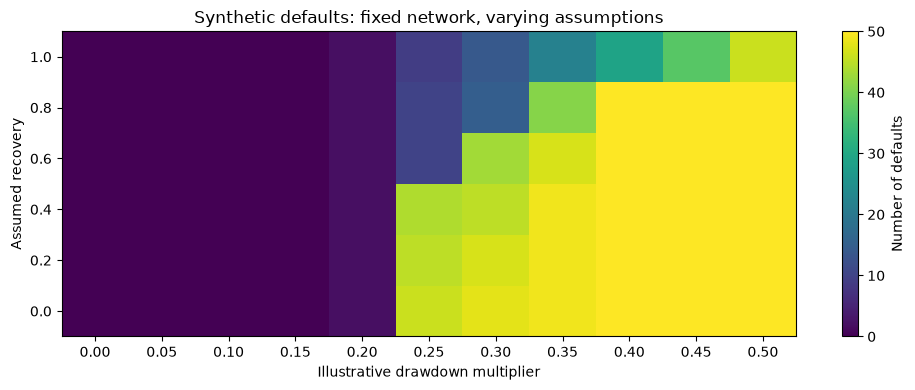

In [7]:
recoveries = np.linspace(0, 1, 6)
multipliers = np.linspace(0, 0.5, 11)
rows = []
for recovery in recoveries:
    for multiplier in multipliers:
        mapping = calibration(multiplier=float(multiplier))
        result = furfine(data, Scenario(recovery=float(recovery), external_impairment=mapping["external_impairment"]))
        rows.append({"recovery": recovery, "multiplier": multiplier,
                     "direct": len(result["initial_defaults"]),
                     "secondary": len(result["secondary_defaults"]),
                     "total": result["default_count"]})
sensitivity = pd.DataFrame(rows)
heatmap = sensitivity.pivot(index="recovery", columns="multiplier", values="total")
fig, ax = plt.subplots(figsize=(10, 4))
plot = ax.imshow(heatmap, origin="lower", aspect="auto", vmin=0, vmax=50, cmap="viridis")
ax.set_xticks(range(len(multipliers)), [f"{x:.2f}" for x in multipliers])
ax.set_yticks(range(len(recoveries)), [f"{x:.1f}" for x in recoveries])
ax.set(xlabel="Illustrative drawdown multiplier", ylabel="Assumed recovery", title="Synthetic defaults: fixed network, varying assumptions")
fig.colorbar(plot, ax=ax, label="Number of defaults")
fig.tight_layout()
sensitivity.to_csv(OUTPUT / "sensitivity.csv", index=False)


## 5. Descriptive topology ensembles

Ten independent generator seeds per family are a small demonstration ensemble. The three generator recipes differ in edge count and exposures and consequently in bank balance sheets and capital amounts. These comparisons therefore concern **generator families**, not the isolated causal effect of topology. Holding bank count fixed does not control density, total exposures or leverage; a properly matched experiment would be needed for that claim. The `scale_free` preset is a randomly oriented Barabási–Albert graph, not proof of an empirically fitted directed power law.

In [8]:
ensemble = topology_ensemble(n=50, seeds=range(10), impairment=0.08, recovery=0.4)
display(ensemble)
ensemble.to_csv(OUTPUT / "topology_ensemble.csv", index=False)


,family,seed,banks,edges,directed_density,total_exposure,total_assets,total_equity,initial_defaults,secondary_defaults,total_defaults,default_fraction,posted_interbank_loss
0,core_periphery,0,50,226,0.092245,5102.289046,29262.987751,2786.657899,3,38,41,0.82,1199.834133
1,core_periphery,1,50,224,0.091429,4930.174157,31497.698001,3157.164982,7,34,41,0.82,1389.937196
2,core_periphery,2,50,228,0.093061,5276.376579,32597.257835,3302.208519,2,36,38,0.76,1429.293869
3,core_periphery,3,50,233,0.095102,5175.101300,30820.198418,2940.490667,10,33,43,0.86,1358.797858
4,core_periphery,4,50,207,0.084490,4900.844533,30612.990134,3013.090115,3,2,5,0.10,145.522624
5,core_periphery,5,50,217,0.088571,4704.566610,30711.081563,3103.753696,4,9,13,0.26,534.250962
6,core_periphery,6,50,207,0.084490,4739.205107,31104.025073,3053.566819,6,29,35,0.70,1328.517076
7,core_periphery,7,50,223,0.091020,5155.420692,32013.752818,3225.131793,3,35,38,0.76,1434.327884
8,core_periphery,8,50,209,0.085306,4754.170541,30349.147198,3272.863098,5,0,5,0.10,125.385060
9,core_periphery,9,50,213,0.086939,4682.193267,31933.201075,3299.180881,5,0,5,0.10,79.280495


## 6. Monte Carlo sampling error versus model uncertainty

We sample independent one-period borrower default events with assumed PD 2%, conditional on a fixed 3% external-asset impairment. Each sample invokes the same deterministic contagion model. The sample standard deviation describes the modeled outcome distribution. `sample SD / sqrt(number of trials)` estimates numerical uncertainty of the simulated mean under independent trials; it does not measure uncertainty about real-world PDs, correlations, recovery, the network, or the model. Empirical tail quantiles with 500 trials can be unstable and are not regulatory risk estimates.

Number of independent trials: 500


,mean,mcse_mean,empirical_q05,empirical_median,empirical_q95
defaults,1.086000,0.048764,0.0,1.000000,3.000000
secondary_defaults,0.040000,0.009218,0.0,0.000000,0.000000
interbank_loss,62.220346,3.719808,0.0,28.316909,223.739971


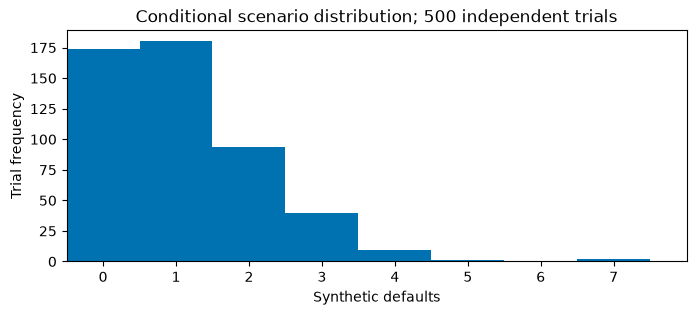

In [9]:
mc_scenario = Scenario(name="Conditional independent-default experiment", external_impairment=0.03, recovery=0.4)
mc = monte_carlo(data, mc_scenario, trials=500, seed=20261030, pd_override=0.02)
summary = monte_carlo_summary(mc)
print("Number of independent trials:", summary["trials"])
display(pd.DataFrame(summary["conditional_summary"]).T)
mc.to_csv(OUTPUT / "monte_carlo_trials.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(mc.defaults, bins=np.arange(52)-0.5, color="#0072b2")
ax.set(xlabel="Synthetic defaults", ylabel="Trial frequency", title="Conditional scenario distribution; 500 independent trials")
ax.set_xlim(-0.5, int(mc.defaults.max()) + 1)
ax.set_xticks(range(int(mc.defaults.max()) + 1));


## 7. Save and replay a complete experiment

The saved JSON includes the input dataset, scenario, output, software version and dataset fingerprint. Replay recomputes the result, rather than trusting a saved number. CSVs above provide inspectable analysis tables. This checks computational reproducibility, not empirical validity.

In [10]:
mapping = calibration(multiplier=0.3)
scenario = Scenario(name="Market-magnitude scenario", external_impairment=mapping["external_impairment"], recovery=0.4)
result = furfine(data, scenario)
parameters = {
    "network": {"banks": 50, "seed": 42, "topology": "core_periphery"},
    "impact_ranking": {"recovery": 0.4, "external_impairment": 0},
    "sensitivity": {"recoveries": recoveries.tolist(), "multipliers": multipliers.tolist()},
    "topology_ensemble": {"banks": 50, "seeds": list(range(10)), "impairment": 0.08, "recovery": 0.4},
    "monte_carlo": {"scenario": mc_scenario.model_dump(), "trials": 500, "seed": 20261030, "pd_override": 0.02},
    "baseline_comparison": {"chain": chain_scenario.model_dump(), "seed42": compare_scenario.model_dump()},
}
(OUTPUT / "parameters.json").write_text(json.dumps(parameters, indent=2, allow_nan=False))
record = experiment(data, result, calibration=mapping, extra={"parameters": parameters, "monte_carlo_summary": summary})
path = save_experiment(record, OUTPUT)
loaded = json.loads(path.read_text())
reloaded = Dataset.model_validate(loaded["dataset"])
assert dataset_hash(reloaded) == loaded["dataset_sha256"]
replay = furfine(reloaded, Scenario.model_validate(loaded["result"]["scenario"]))
assert replay == loaded["result"]
print("Replay verified:", path.name)
print("Defaults:", replay["default_count"], "direct:", len(replay["initial_defaults"]), "secondary:", len(replay["secondary_defaults"]))


Replay verified: experiment_c2278e4e03fc47f98c1ffb57e2e65642.json
Defaults: 45 direct: 14 secondary: 31


## Defensible conclusions and next steps

1. The implementation reproduces the independently calculated three-bank cascade and checks accounting before simulation.
2. On the displayed synthetic inputs, shocks and recovery assumptions generate the recorded loss and default paths. These are conditional computational results.
3. Impact ranking and graph centrality answer different questions. Topology ensembles are descriptive unless financial margins and density are controlled.
4. Historical market observations do not identify bilateral loans, bank PDs or historical bank failures. The multiplier is an illustrative bridge to a stress scenario.
5. Future validation needs independent implementation checks, empirical balance-sheet and exposure information, sensitivity to dependence and recovery, and—if visual analytics claims are pursued—a separate user study.

**Model references:** Furfine, [BIS Working Paper 70](https://www.bis.org/publ/work70.htm); Battiston et al., [DebtRank (2012)](https://www.nature.com/articles/srep00541). The implemented variants and exclusions are documented in `docs/MODELS.md`.